In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline

In [ ]:
df = pd.read_csv("diabetes.csv")

print("First 5 Rows:")
print(df.head())

print("\nShape of Dataset:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

First 5 Rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148           72.0             35    169.5  33.6   
1            1       85           66.0             29    102.5  26.6   
2            8      183           64.0             32    169.5  23.3   
3            1       89           66.0             23     94.0  28.1   
4            0      137           40.0             35    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Shape of Dataset:
(768, 9)

Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


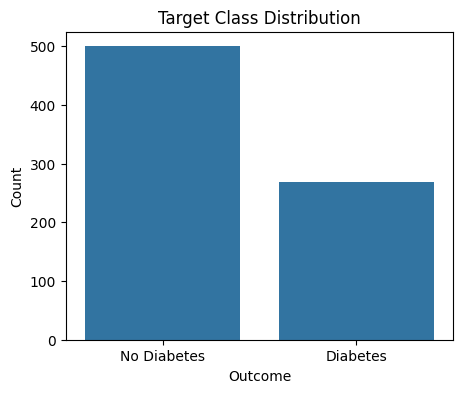


Target Class Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(5,4))
sns.countplot(x='Outcome', data=df)
plt.title("Target Class Distribution")
plt.xticks([0,1], ['No Diabetes', 'Diabetes'])
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.show()

print("\nTarget Class Distribution:")
print(df['Outcome'].value_counts())

In [ ]:
columns_to_fix = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

before_treatment = df.copy()

for col in columns_to_fix:
    median = df[df[col] != 0][col].median()
    df[col] = df[col].replace(0, median)

print("\nZero values replaced with column medians.")


Zero values replaced with column medians.


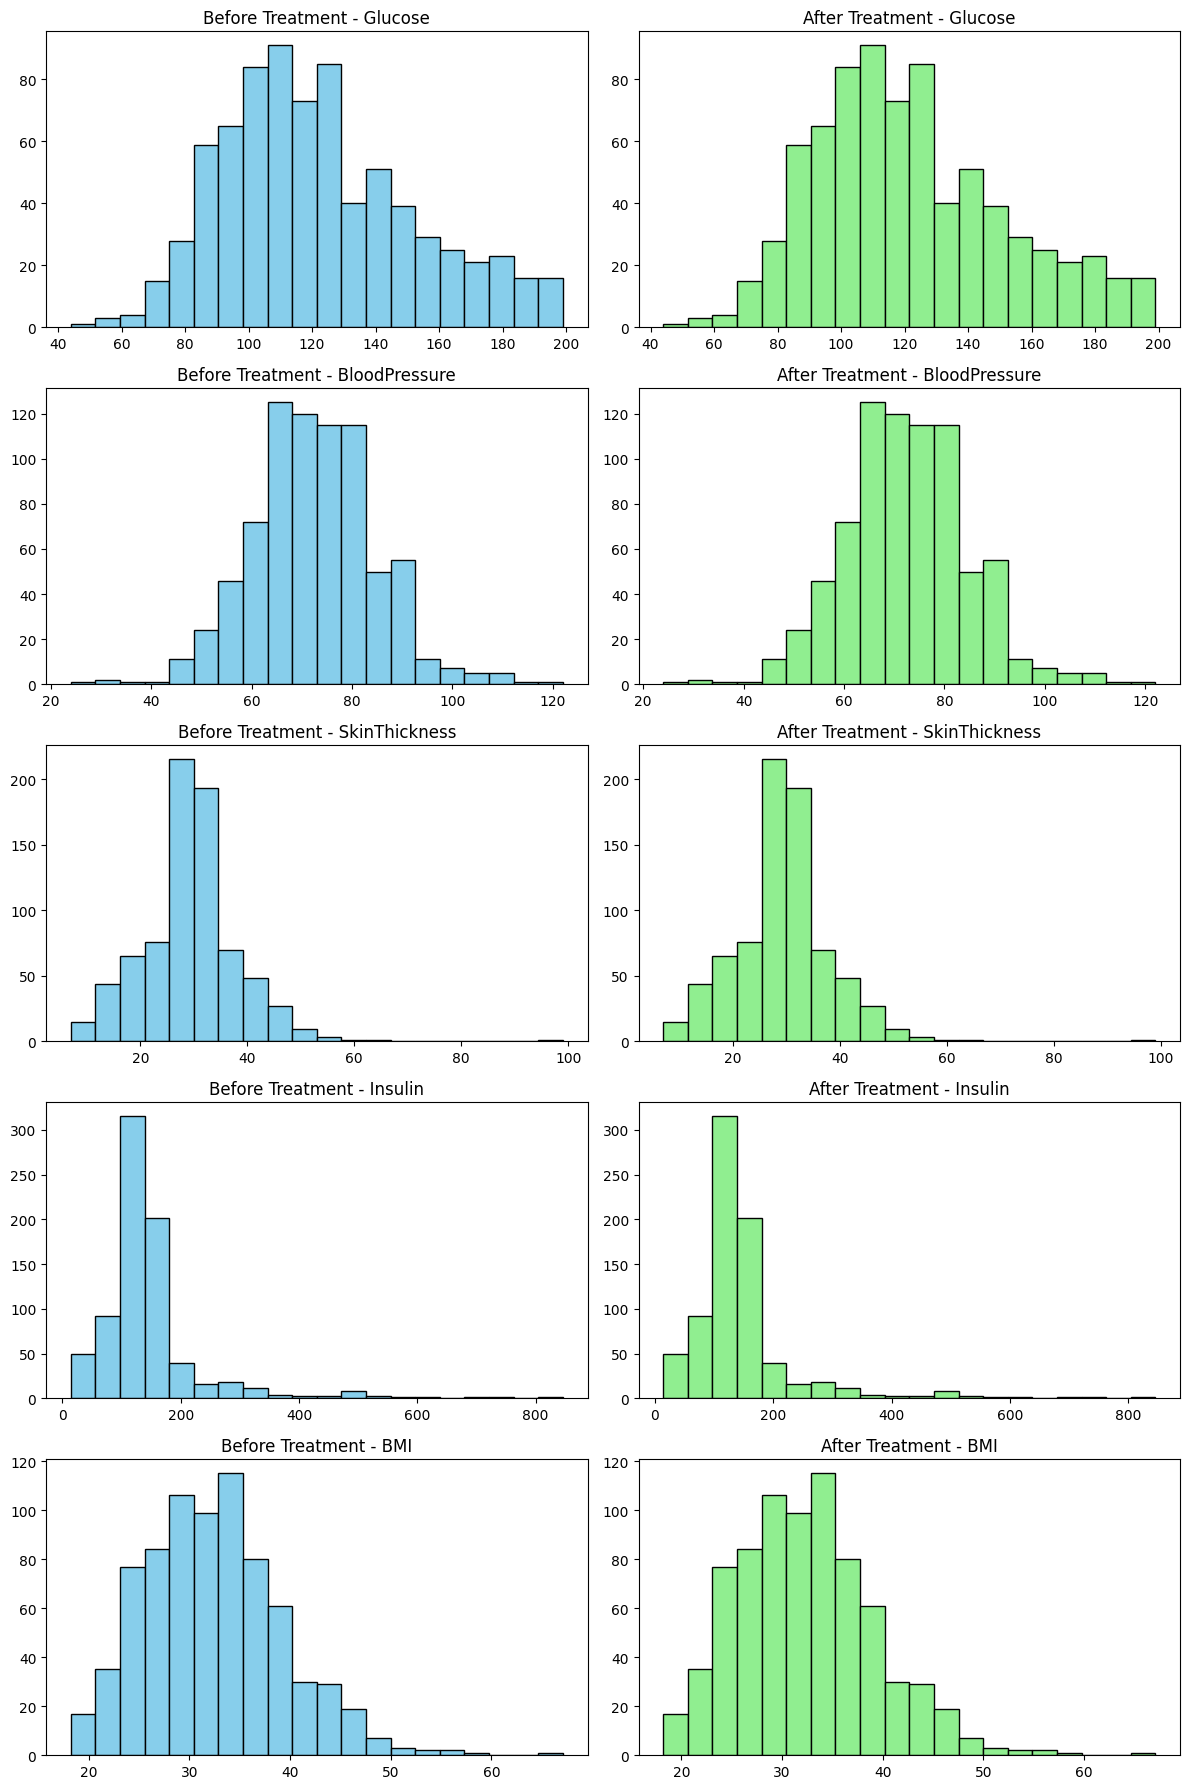

In [ ]:
fig, axes = plt.subplots(len(columns_to_fix), 2, figsize=(12,18))

for i, col in enumerate(columns_to_fix):
    axes[i,0].hist(before_treatment[col], bins=20, color='skyblue', edgecolor='black')
    axes[i,0].set_title(f"Before Treatment - {col}")

    axes[i,1].hist(df[col], bins=20, color='lightgreen', edgecolor='black')
    axes[i,1].set_title(f"After Treatment - {col}")

plt.tight_layout()
plt.show()

In [ ]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

In [ ]:
k_values = [1, 3, 5, 7, 9, 11]
accuracies = []

for k in k_values:
    knn_pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k))
    ])
    knn_pipe.fit(X_train, y_train)
    y_pred_knn = knn_pipe.predict(X_test)
    acc = accuracy_score(y_test, y_pred_knn)
    accuracies.append(acc)
    print(f"K = {k} -> Test Accuracy = {round(acc, 4)}")

K = 1 -> Test Accuracy = 0.7344
K = 3 -> Test Accuracy = 0.776
K = 5 -> Test Accuracy = 0.776
K = 7 -> Test Accuracy = 0.7969
K = 9 -> Test Accuracy = 0.7917
K = 11 -> Test Accuracy = 0.7969


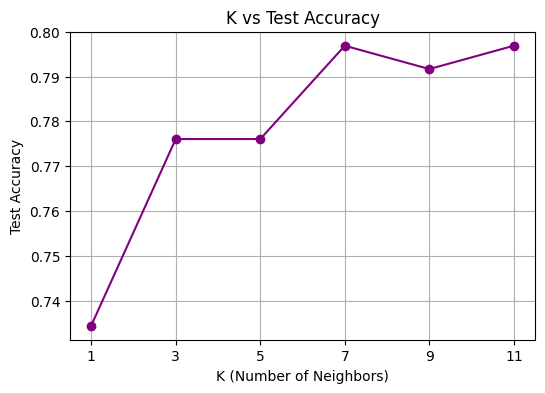

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(k_values, accuracies, marker='o', color='purple')
plt.title("K vs Test Accuracy")
plt.xlabel("K (Number of Neighbors)")
plt.ylabel("Test Accuracy")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [ ]:
best_index = accuracies.index(max(accuracies))
best_k = k_values[best_index]

print("Optimal K:", best_k)
print("Best Test Accuracy:", round(max(accuracies), 4))

Optimal K: 7
Best Test Accuracy: 0.7969


In [ ]:
pipelines = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=best_k))
    ]),
    "Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ])
}

results = []

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

comparison = pd.DataFrame(results)
comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.744792,0.651515,0.623188,0.637037
1,KNN,0.796875,0.708333,0.739130,0.723404
2,Naive Bayes,0.744792,0.638889,0.666667,0.652482


KNN IS THE BEST MODEL AS IT BEATS BOTH LINEAR REGRESSION AND NAIVE BAIS IN TERMS OF ACCURACY,PRECISION,RECALL,F1-SCORE